In [1]:
import sys
sys.path.append("../..")

from analysis.utils import get_runs_data, show_config_differences, filter_data
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

# Set default font sizes for all plots
plt.rcParams['font.size'] = 14          # Default font size
plt.rcParams['axes.titlesize'] = 18     # Title font size
plt.rcParams['axes.labelsize'] = 16     # Axis label font size
plt.rcParams['xtick.labelsize'] = 14    # X-axis tick label font size
plt.rcParams['ytick.labelsize'] = 14    # Y-axis tick label font size
plt.rcParams['legend.fontsize'] = 14    # Legend font size

# Hybrid synthetic and wikitext

Where synthetic sequences are constructed from `n` random tokens from vocab.

In [2]:
data = get_runs_data(
    tag="week8-synthetic-tokens", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ]
)

wandb: Currently logged in as: r-alvarezlucendo16 (minigpttu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Found 4 runs with tag 'week8-synthetic-tokens'


In [3]:
show_config_differences(data)

,cfg.dataset.token_subset_size
_run_id,
17rz74h8,10000
gptv6h5u,100
j3yqmi3y,10
xhypvi3n,1000


## Synthetic (10 tokens)

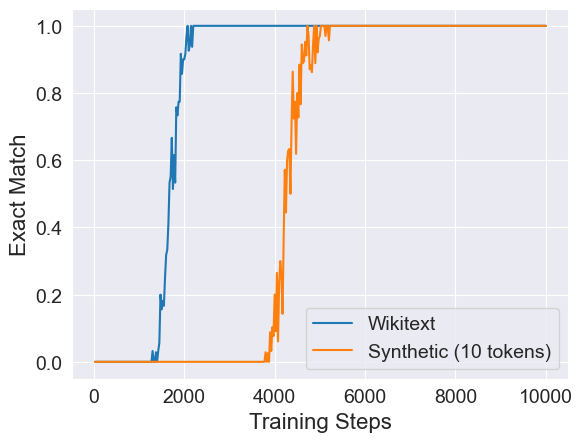

In [4]:
n = 10

filtered_data = filter_data(data, {"cfg.dataset.token_subset_size": n})
em_wiki = filtered_data["train/exact_match_wikitext"]
em_synth = filtered_data["train/exact_match_synthetic"]
steps = filtered_data["train/global_step"]

plt.plot(steps, em_wiki, label="Wikitext")
plt.plot(steps, em_synth, label=f"Synthetic ({n} tokens)")
plt.xlabel("Training Steps")
plt.ylabel("Exact Match")
plt.legend()
plt.savefig(f"../figures/synthetic_vs_wikitext_{n}_tokens.pdf")


## Synthetic (100 tokens)

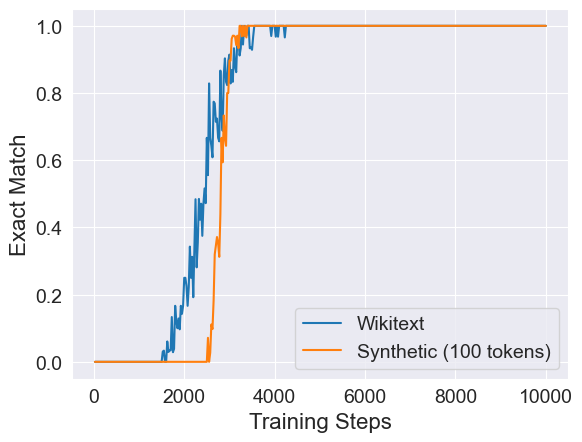

In [5]:
n = 100

filtered_data = filter_data(data, {"cfg.dataset.token_subset_size": n})
em_wiki = filtered_data["train/exact_match_wikitext"]
em_synth = filtered_data["train/exact_match_synthetic"]
steps = filtered_data["train/global_step"]

plt.plot(steps, em_wiki, label="Wikitext")
plt.plot(steps, em_synth, label=f"Synthetic ({n} tokens)")
plt.xlabel("Training Steps")
plt.ylabel("Exact Match")
plt.legend()
plt.savefig(f"../figures/synthetic_vs_wikitext_{n}_tokens.pdf")

## Synthetic (1000 tokens)

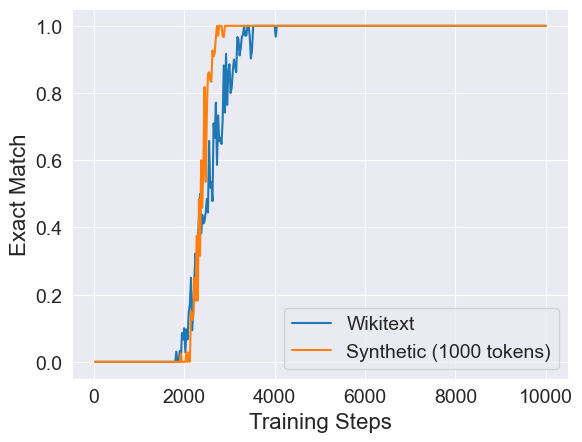

In [6]:
n = 1000

filtered_data = filter_data(data, {"cfg.dataset.token_subset_size": n})
em_wiki = filtered_data["train/exact_match_wikitext"]
em_synth = filtered_data["train/exact_match_synthetic"]
steps = filtered_data["train/global_step"]

plt.plot(steps, em_wiki, label="Wikitext")
plt.plot(steps, em_synth, label=f"Synthetic ({n} tokens)")
plt.xlabel("Training Steps")
plt.ylabel("Exact Match")
plt.legend()
plt.savefig(f"../figures/synthetic_vs_wikitext_{n}_tokens.pdf")

## Synthetic (10000 tokens)

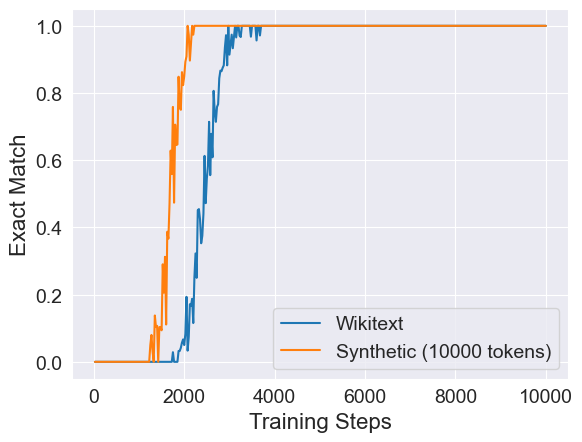

In [7]:
n = 10000

filtered_data = filter_data(data, {"cfg.dataset.token_subset_size": n})
em_wiki = filtered_data["train/exact_match_wikitext"]
em_synth = filtered_data["train/exact_match_synthetic"]
steps = filtered_data["train/global_step"]

plt.plot(steps, em_wiki, label="Wikitext")
plt.plot(steps, em_synth, label=f"Synthetic ({n} tokens)")
plt.xlabel("Training Steps")
plt.ylabel("Exact Match")
plt.legend()
plt.savefig(f"../figures/synthetic_vs_wikitext_{n}_tokens.pdf")

# Synthetic vs wikitext [only repeating sequences]

In [8]:
data = get_runs_data(
    tag="week8-only-repeated", 
    metrics=[
        "train/exact_match_repeated"
    ]
)

Found 3 runs with tag 'week8-only-repeated'


In [9]:
show_config_differences(data)

,cfg.dataset._target_,cfg.dataset.shuffle_fresh_pool
_run_id,,
l1hnz0va,dataset.WikiTextDataset,False
mnuzch6b,dataset.synthetic.SyntheticDataset,None
zlgihrqw,dataset.WikiTextDataset,True


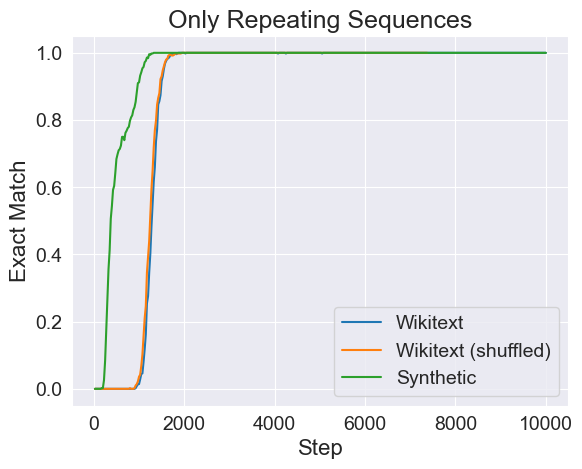

In [10]:
groups = data.groupby(["cfg.dataset._target_", "cfg.dataset.shuffle_fresh_pool"], dropna=False)[["train/exact_match_repeated", "train/global_step"]]
for (dataset_target, shuffle_fresh_pool), group in groups:
    em_repeated = group["train/exact_match_repeated"]
    steps = group["train/global_step"]
    dataset_type = "Wikitext" if "Wiki" in dataset_target else "Synthetic"
    label = dataset_type
    if dataset_type == "Wikitext" and shuffle_fresh_pool:
        label += " (shuffled)"
    plt.plot(steps, em_repeated, label=label)

plt.xlabel("Step")
plt.ylabel("Exact Match")
plt.title("Only Repeating Sequences")
plt.legend()
plt.savefig(f"../figures/only_repeating_sequences.pdf")